# Детекция ArUco маркеров

Используются классы проекта:

- `PhotoArucoDetector` — обработка одиночного фото
- `VideoArucoDetector` — покадровая обработка видео
- `ArucoDetect` — общий детектор: матрица камеры, `solvePnP`, отрисовка

Запускать из корня проекта (`photo-opu`), ядро — `.venv`. Окна OpenCV не используются, результат выводится через matplotlib.


In [6]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.base import DetectionResult
from src.config import settings
from src.detectors import PhotoArucoDetector, VideoArucoDetector


def show_image(image: np.ndarray, title: str = "Результат") -> None:
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


In [7]:
MARKER_SIZE = 0.2
RUN_NAME = "detection_marker_move_1"

PHOTO_PATH = settings.input_photo / "test_photo.png"
PHOTO_OUTPUT_PATH = settings.output_photo / "test_result.jpg"

VIDEO_PATH = settings.input_video / "marker_move_1.mov"
VIDEO_OUTPUT_PATH = settings.output_video / RUN_NAME / f"{RUN_NAME}.mp4"


## Генерация ArUco-меток


In [8]:
# from src.utils import generate_aruco_markers

# generated = generate_aruco_markers(count=6, marker_type="4x4")
# print(f"Сгенерировано меток: {len(generated)} в {settings.aruco_markers}")
# for path in generated:
#     print(path.name)


## Фото


Найдено маркеров: 3
ID: [1, 2, 0]
Маркер ID=1: tvec=[0.426 0.189 2.132], центр в координатах камеры=[0.426 0.189 2.132]
Маркер ID=2: tvec=[-0.427  0.224  2.106], центр в координатах камеры=[-0.427  0.224  2.106]
Маркер ID=0: tvec=[-0.03  -0.536  2.177], центр в координатах камеры=[-0.03  -0.536  2.177]
Маркеры найдены на изображении test_photo.png: True


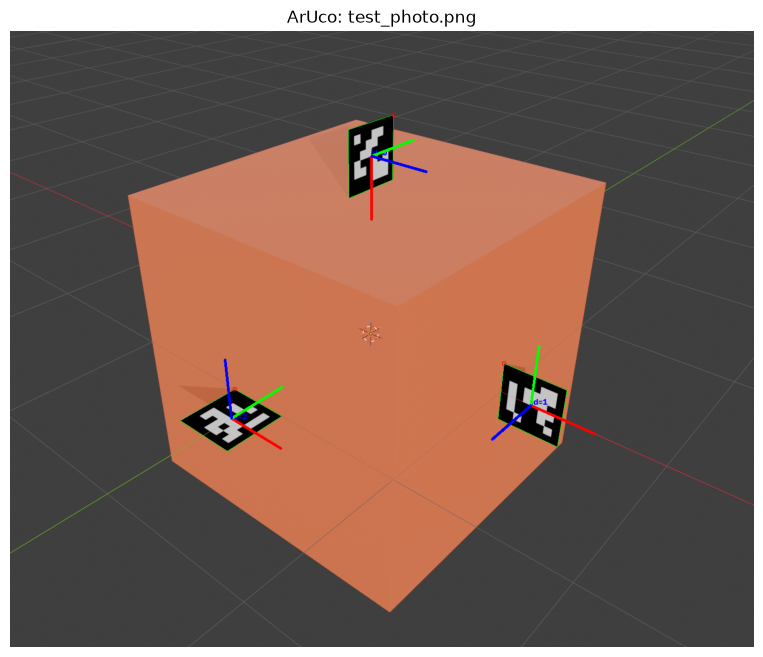

In [9]:
import os

with PhotoArucoDetector(marker_size=MARKER_SIZE) as detector:
    photo_results = {}
    for photo_path in sorted(settings.input_photo.iterdir()):
        output_path = settings.output_photo / photo_path.name
        photo_results[photo_path.name] = detector.process(
            photo_path,
            output_path,
            show=False,
            save=True,
        )

for name, result in photo_results.items():
    print(f"Маркеры найдены на изображении {name}: {result.found}")
    show_image(result.image, f"ArUco: {name}")


## Видео


Кадр 1/481: ID [0]
Кадр 2/481: ID [0]
Кадр 3/481: ID [0]
Кадр 4/481: ID [0]
Кадр 5/481: ID [0]
Кадр 6/481: ID [0]
Кадр 7/481: ID [0]
Кадр 8/481: ID [0]
Кадр 9/481: ID [0]
Кадр 10/481: ID [0]
Кадр 11/481: ID [0]
Кадр 12/481: ID [0]
Кадр 13/481: ID [0]
Кадр 14/481: ID [0]
Кадр 15/481: ID [0]
Кадр 16/481: ID [0]
Кадр 17/481: ID [0]
Кадр 18/481: ID [0]
Кадр 19/481: ID [0]
Кадр 20/481: ID [0]
Кадр 21/481: ID [0]
Кадр 22/481: ID [0]
Кадр 23/481: ID [0]
Кадр 24/481: ID [0]
Кадр 25/481: ID [0]
Кадр 26/481: ID [0]
Кадр 27/481: ID [0]
Кадр 28/481: ID [0]
Кадр 29/481: ID [0]
Кадр 30/481: ID [0]
Кадр 31/481: ID [0]
Кадр 32/481: ID [0]
Кадр 33/481: ID [0]
Кадр 34/481: ID [0]
Кадр 35/481: ID [0]
Кадр 36/481: ID [0]
Кадр 37/481: ID [0]
Кадр 38/481: ID [0]
Кадр 39/481: ID [0]
Кадр 40/481: ID [0]
Кадр 41/481: ID [0]
Кадр 42/481: ID [0]
Кадр 43/481: ID [0]
Кадр 44/481: ID [0]
Кадр 45/481: ID [0]
Кадр 46/481: ID [0]
Кадр 47/481: ID [0]
Кадр 48/481: ID [0]
Кадр 49/481: ID [0]
Кадр 50/481: ID [0]
Кадр 51/4

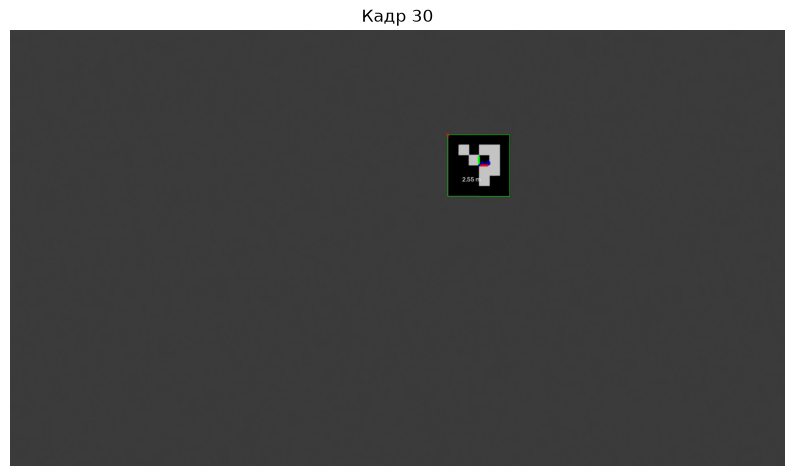

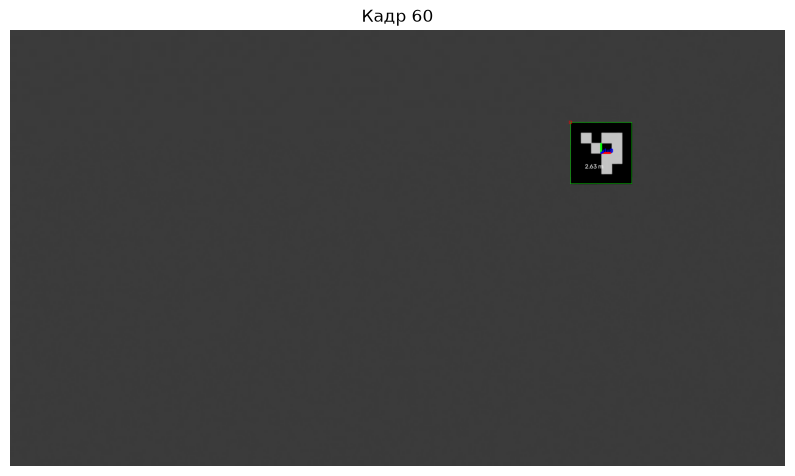

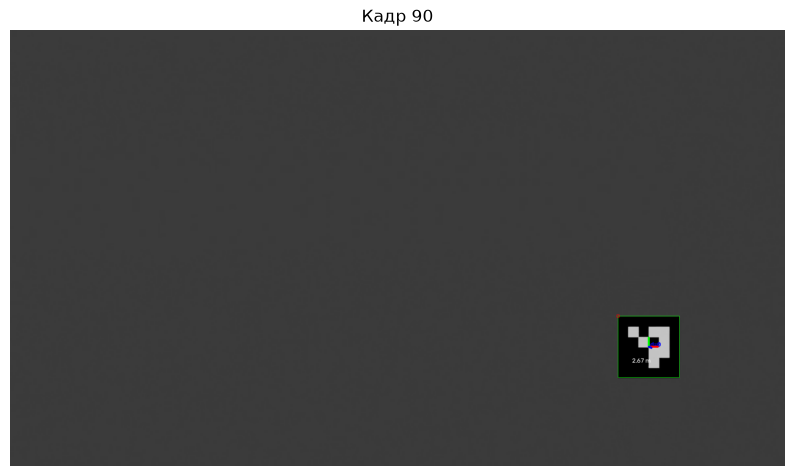

In [10]:
samples: list[DetectionResult] = []

with VideoArucoDetector(marker_size=MARKER_SIZE, dict_id=cv2.aruco.DICT_4X4_50) as detector:
    for frame_result in detector.process(VIDEO_PATH, VIDEO_OUTPUT_PATH, show=False):
        frame_index = frame_result.frame_index or 0
        if frame_result.found and len(samples) < 3 and frame_index % 30 == 0:
            samples.append(frame_result)

stats_path = VIDEO_OUTPUT_PATH.with_suffix(".csv")
print(f"Видео и статистика сохранены в: {VIDEO_OUTPUT_PATH.parent}")
print(pd.read_csv(stats_path, sep=";").to_string(index=False))

for sample in samples:
    show_image(sample.image, f"Кадр {sample.frame_index}")
